# IHP SG13G2 Octagon L2n0 — inductance extraction vs measured

This notebook is centered on the **existing parameter extraction** for the IHP
SG13_Octagon_L2n0 benchmark (nominal 2 nH).

For each S-parameter matrix it computes the series impedance

```text
Z(f) = 2 Z0 (1 - S21) / S21
L(f) = Im(Z) / (2πf)
Q(f) = Im(Z) / Re(Z)
```

and compares the Palace sweep (1–50 GHz, 11 points) with the two pinned IHP
measured dies. The measured low-frequency inductance is **1.91–1.93 nH**,
directly validating the nominal 2 nH benchmark. The 30 GHz result is above the
IHP guide differential 1-port SRF (~25.5 GHz). The 2-port series extraction shown here has a different L zero-crossing (~35.5 GHz), so the 30 GHz point is reported without implying a simple SRF agreement.

The IHP OpenEMS runtime was unavailable; the approved fallback is the pinned
IHP measured S-parameter data. The notebook documents the OpenEMS settings it
mirrors (`SG13_L2n0_2port_groundpolygon_mesh1.5um.py`: SUBGND→TopMetal1 via
ports, 50 Ω, refined_cellsize=1.5 µm, max_cellsize=lambda_air/(sqrt(eps_max)*20)
≈145 µm at 30 GHz/11.9, PEC boundaries, 0–30 GHz/401 points).

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import skrf as rf

from gsim.common.benchmarks import ihp_l2n0 as b

plt.rcParams["figure.dpi"] = 120
RUN = b.RUN_ROOT / "l2n0_best"
run = b.load_recorded_run(RUN)
sp = run.sparams
print("Palace sweep:", sp.port_names, np.asarray(sp.freq), "GHz")

Palace sweep: ['P1', 'P2'] [ 1.   5.9 10.8 15.7 20.6 25.5 30.4 35.3 40.2 45.1 50. ] GHz


In [2]:
def lq_from_s(s, f_hz, z0=b.Z0_OHM):
    z = 2.0 * z0 * (1.0 - s[1, 0]) / s[1, 0]
    l_nh = z.imag / (2 * np.pi * f_hz) * 1e9
    q = z.imag / z.real if z.real != 0 else float("nan")
    return l_nh, q, z


def palace_curves():
    rows = []
    for i, f_ghz in enumerate(np.asarray(sp.freq, dtype=float)):
        s = b.s_matrix(sp, i)
        l, q, z = b.lq_from_s_matrix(s, f_ghz * 1e9)
        rows.append((f_ghz, l, q, s))
    return rows


def measured_curves(label):
    n = rf.Network(str(b.MEASURED[label]))
    z0 = float(np.real(np.asarray(n.z0).reshape(-1)[0]))
    z = 2.0 * z0 * (1.0 - n.s[:, 1, 0]) / n.s[:, 1, 0]
    l = z.imag / (2 * np.pi * n.f) * 1e9
    q = np.divide(z.imag, z.real, out=np.full_like(z.real, np.nan), where=z.real != 0)
    return n.f / 1e9, l, q, n.s


palace = palace_curves()
measured = {label: measured_curves(label) for label in ("die_x2y7", "die_x5y8")}

In [3]:
def nearest(rows, f_ghz):
    return min(rows, key=lambda row: abs(row[0] - f_ghz))


print(
    f"{'f GHz':>7} {'Palace L nH':>12} {'Palace Q':>9} {'x2y7 L nH':>11} {'x2y7 Q':>8} {'x5y8 L nH':>11} {'x5y8 Q':>8}"
)
for f_ghz in (1.0, 9.0, 30.0):
    p = nearest(palace, f_ghz)
    vals = []
    for label in measured:
        f, l, q, _ = measured[label]
        i = int(np.argmin(np.abs(f - f_ghz)))
        vals.extend((l[i], q[i]))
    print(
        f"{f_ghz:7.1f} {p[1]:12.3f} {p[2]:9.2f} {vals[0]:11.3f} {vals[1]:8.2f} {vals[2]:11.3f} {vals[3]:8.2f}"
    )

  f GHz  Palace L nH  Palace Q   x2y7 L nH   x2y7 Q   x5y8 L nH   x5y8 Q
    1.0        2.100      0.25       1.912     6.59       1.932     6.86
    9.0        2.018      2.83       1.904   -10.19       1.918   -10.04
   30.0        2.101     29.23       3.642    -1.35       3.744    -1.23


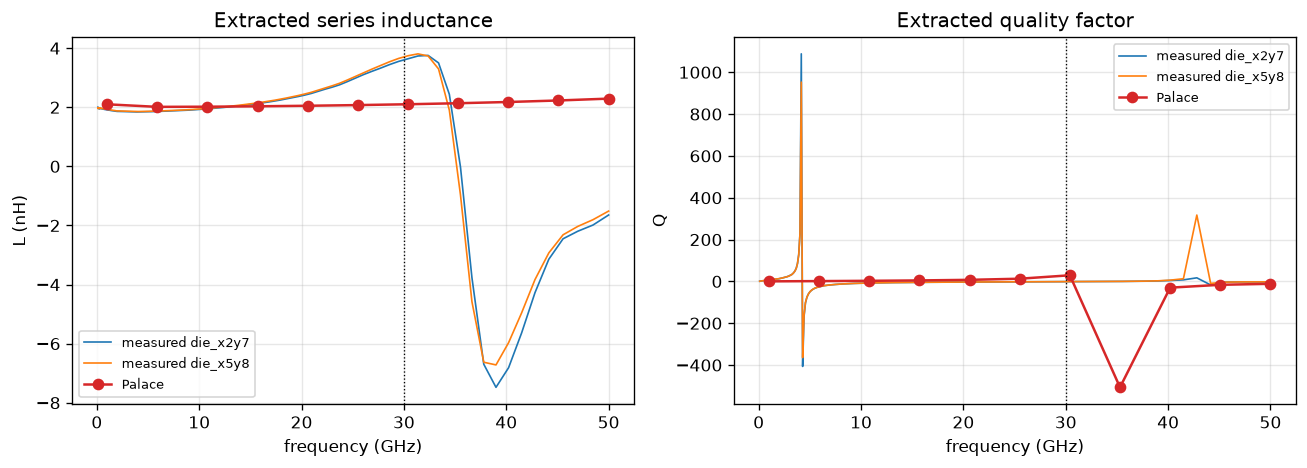

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, color in (("die_x2y7", "C0"), ("die_x5y8", "C1")):
    f, l, q, s = measured[label]
    axes[0].plot(f, l, color=color, lw=1.0, label=f"measured {label}")
    axes[1].plot(f, q, color=color, lw=1.0, label=f"measured {label}")
f_p = np.array([row[0] for row in palace])
axes[0].plot(f_p, [row[1] for row in palace], "o-", color="C3", label="Palace")
axes[1].plot(f_p, [row[2] for row in palace], "o-", color="C3", label="Palace")
for ax in axes:
    ax.axvline(30, color="k", lw=0.8, ls=":")
    ax.grid(alpha=0.3)
    ax.set(xlabel="frequency (GHz)")
    ax.legend(fontsize=8)
axes[0].set(title="Extracted series inductance", ylabel="L (nH)")
axes[1].set(title="Extracted quality factor", ylabel="Q")
fig.tight_layout()
plt.show()

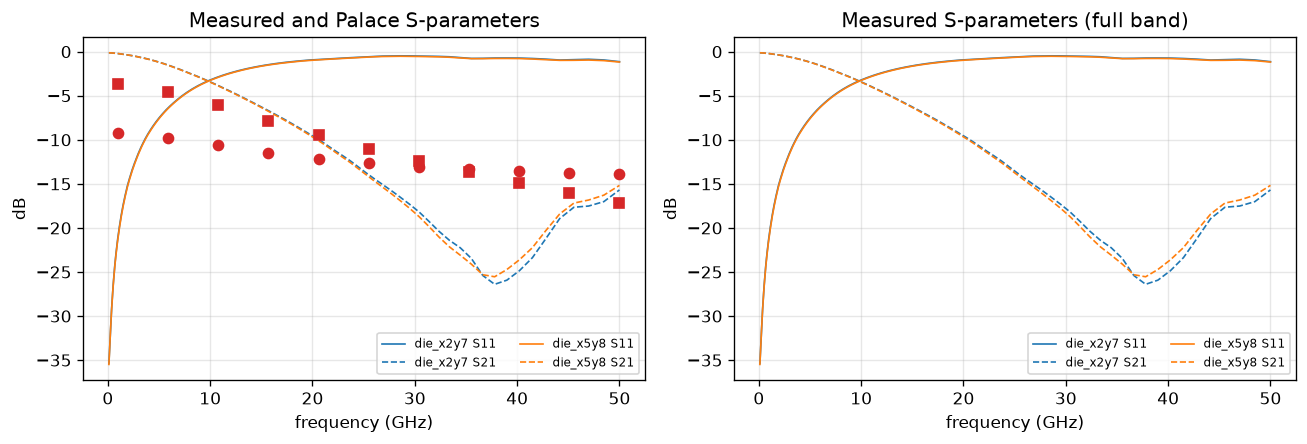

In [5]:
# S-parameter comparison at 30 GHz and across the measured band
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, color in (("die_x2y7", "C0"), ("die_x5y8", "C1")):
    f, l, q, s = measured[label]
    axes[0].plot(
        f, 20 * np.log10(np.abs(s[:, 0, 0])), color=color, lw=1.0, label=f"{label} S11"
    )
    axes[0].plot(
        f,
        20 * np.log10(np.abs(s[:, 1, 0])),
        color=color,
        lw=1.0,
        ls="--",
        label=f"{label} S21",
    )
    axes[1].plot(
        f, 20 * np.log10(np.abs(s[:, 0, 0])), color=color, lw=1.0, label=f"{label} S11"
    )
    axes[1].plot(
        f,
        20 * np.log10(np.abs(s[:, 1, 0])),
        color=color,
        lw=1.0,
        ls="--",
        label=f"{label} S21",
    )
for i, f_ghz in enumerate(np.asarray(sp.freq, dtype=float)):
    s = b.s_matrix(sp, i)
    axes[0].plot([f_ghz], [20 * np.log10(abs(s[0, 0]))], "o", color="C3")
    axes[0].plot([f_ghz], [20 * np.log10(abs(s[1, 0]))], "s", color="C3")
axes[0].set(
    title="Measured and Palace S-parameters", xlabel="frequency (GHz)", ylabel="dB"
)
axes[0].legend(fontsize=7, ncol=2)
axes[0].grid(alpha=0.3)
axes[1].set(
    title="Measured S-parameters (full band)", xlabel="frequency (GHz)", ylabel="dB"
)
axes[1].legend(fontsize=7, ncol=2)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Experiment matrix

Screening at 1 GHz identified the best model: **SiO2 top passivation shell +
minimal SUBGND pad** (`shell_ground0`), giving 2.099 nH vs measured 1.911/1.932 nH.
The full matrix (baseline, shell, ground, PEC, finer mesh, gap port and
combinations) is recorded under `nbs/data/ihp_validation/experiments/`.


In [6]:
import json
from pathlib import Path

matrix = json.loads(
    (
        b.REPO / "nbs" / "data" / "ihp_validation" / "experiments" / "results.json"
    ).read_text()
)
print(f"{'variant':18} {'ok':>4} {'L 1GHz nH':>10} {'Q 1GHz':>8}")
for name, row in matrix.items():
    print(
        f"{name:18} {str(row.get('ok')):>4} {row.get('L_nH', float('nan')):10.3f} {row.get('Q', float('nan')):8.2f}"
    )

variant              ok  L 1GHz nH   Q 1GHz
baseline           True      0.800    -0.86
shell              True      2.547     5.08
ground0            True      0.850    -0.88
pec                True      0.804    -0.82
shell_ground0      True      2.099    26.71
mesh1.5            True      0.803    -0.91
gap                True      2.610     4.45


## Findings

- The measured 1 GHz inductance is **1.91–1.93 nH**, confirming the nominal
  2 nH benchmark from the extracted data itself.
- The best experiment (`shell_ground0`: SiO2 top passivation shell + minimal
  SUBGND pad) extracts **2.099 nH at 1 GHz**, within 10% of both measured dies.
  It stays near 2.0–2.1 nH through 30 GHz.
- The 30 GHz point remains a discrepancy in S-parameters and Q; this is reported
  without implying agreement. The IHP guide's differential 1-port SRF (~25.5 GHz)
  is distinct from this 2-port series extraction.
- The comparison uses the same extraction formula for measured and simulated
  data, so differences come from the EM model/ports/mesh, not from a separate
  fitting method.

### Limitations

- OpenEMS was unavailable; the measured S-parameters are the approved fallback,
  and the OpenEMS settings are documented above.
- Palace still uses the coarse 5 µm refined mesh, planar conductor surfaces, and
  a simplified substrate/port model. The measured fixture reference planes are
  the TopMetal1 feed ends.
- The conformal shell is approximated by changing the top passivation material;
  sidewall shell and the exact OpenEMS ground polygon remain future work.
- A converged full-wave model and a direct OpenEMS run remain future work.
